# Демо 2 · Текстовий пошук по аеровідео: SigLIP 2 vs RemoteCLIP vs SkyCLIP

**Заняття 5 · Vision Transformers та мультимодальні моделі** · слайди 32, 36, 41, 44, 47–51

Оператору треба знайти у відеоархіві «вантажівку біля будівлі», не переглядаючи години записів.
Ноутбук будує повний конвеєр і чесно вимірює, що працює:

| Що показуємо | Слайд |
|---|---|
| Ключові кадри → ембеддинги → FAISS → ранжований список кадрів з таймкодами | 32, 41 |
| Вебова модель (SigLIP 2) проти доменних (RemoteCLIP, SkyCLIP) на тих самих кадрах | 36 |
| Промпт `"a truck"` проти ансамблю з вказівкою ракурсу (`"an aerial photo of a truck"`, …) | 36 |
| Увесь кадр на вході моделі проти тайлів: пікселі на цілі вирішують | 22, 23 |
| Метрики пошуку: EventRecall@k, P@k — а не accuracy | 44 |
| Розподіли сирого cos і де ставити поріг для оператора | 47 |
| PQ-коди замість векторів: скільки пошуку лишається в каналі 1.5–6 кбіт/с | 48–51 |

**Підготовка (один раз, з мережею):**
```bash
# з кореня репозиторію
python tools/fetch_clip_models.py    # ваги трьох моделей -> artifacts/models/clip/ (+ manifest.json з SHA-256)
python tools/fetch_visdrone.py       # VisDrone-VID val + test-dev -> artifacts/visdrone/
```
Далі ноутбук сам переходить в офлайн: якщо в `artifacts/models/clip/manifest.json` є всі потрібні моделі, звернень до HF Hub немає.

**Швидка перевірка середовища без мережі:** `DEMO2_SMOKE=1 jupyter nbconvert --execute ...` —
синтетичні кадри й випадкові ваги. Числа тоді беззмістовні, перевіряється лише, що конвеєр працює.

In [2]:
import os, sys, subprocess, json, time
from pathlib import Path

SMOKE = os.environ.get("DEMO2_SMOKE") == "1"

# ---------------- Конфігурація ----------------
DATASET = "visdrone"            # "visdrone" — авто-GT з розмітки; "own" — своє відео + gt/own_queries.csv
VISDRONE_SPLITS = ["val", "test-dev"]
OWN_GT_CSV = Path("gt/own_queries.csv")      # GT лишається в теці заняття, відео — в artifacts/aerial_video

MODELS = ["siglip2", "remoteclip", "skyclip"]
SIZE = "base"                   # "base": SigLIP2 B/16, RemoteCLIP B/32, SkyCLIP B/32 | "large": L/16, L/14, L/14

SAMPLE_FPS = 3.0                # VisDrone — хвилини відео, беремо щільніше; для години власного польоту — 1.0
DEDUP_THR = 2.0                 # 0 — без дедуплікації (статична камера, див. докстрінг)
TILE_GRID = (2, 3)              # None — лише увесь кадр
TILE_OVERLAP = 0.15
MIN_PX = 24                     # мінімальна коротка сторона цілі (px вихідного кадру) для GT
BATCH = 64
DEVICE = 'cuda'                   # None = cuda / mps / cpu автоматично

import aerial_search as A    # імпорт до HF_HOME безпечний: torch / open_clip вантажаться лише в Encoder

# Дані й ваги — в artifacts/ у корені репозиторію (кладуть tools/fetch_*.py), кеш кадрів і ембеддингів — в outputs/.
VISDRONE_DIR, OWN_VIDEO_DIR, MODELS_DIR = A.VISDRONE_DIR, A.OWN_VIDEO_DIR, A.MODELS_DIR
CACHE_DIR = Path("outputs/demo2")
if SMOKE:
    VISDRONE_DIR, CACHE_DIR = Path("outputs/smoke/visdrone"), Path("outputs/smoke/cache")
    DATASET, SAMPLE_FPS, DEDUP_THR, MIN_PX, BATCH = "visdrone", 5.0, 0.0, 20, 32

os.environ.setdefault("HF_HOME", str(A.HF_HOME))
# Якщо tools/fetch_clip_models.py уже завантажив усі потрібні ваги — працюємо офлайн: жодних звернень до HF Hub
# (і без попередження про HF_TOKEN). Діє лише до першого імпорту huggingface_hub, тобто після перезапуску ядра.
_manifest = MODELS_DIR / "manifest.json"
if not SMOKE and _manifest.exists() and all(f"{m}-{SIZE}" in json.loads(_manifest.read_text()) for m in MODELS):
    os.environ.setdefault("HF_HUB_OFFLINE", "1")

import numpy as np, pandas as pd
from PIL import Image
pd.set_option("display.precision", 3)
print("SMOKE" if SMOKE else "FULL", "| dataset:", DATASET, "| models:", MODELS, SIZE,
      "| HF:", "offline" if os.environ.get("HF_HUB_OFFLINE") == "1" else "online")

FULL | dataset: visdrone | models: ['siglip2', 'remoteclip', 'skyclip'] base | HF: offline


## 1. Дані

In [3]:
if SMOKE:
    A.make_synthetic_visdrone(VISDRONE_DIR, n_seq=3, n_frames=60)
elif DATASET == "visdrone" and not any(VISDRONE_DIR.rglob("sequences")):
    subprocess.run([sys.executable, str(A.REPO_ROOT / "tools" / "fetch_visdrone.py"),
                    "--splits", *VISDRONE_SPLITS], check=True)

if DATASET == "visdrone":
    sources = A.discover_visdrone(VISDRONE_DIR)
else:
    sources = A.discover_generic(OWN_VIDEO_DIR)
assert sources, f"Джерел не знайдено в {VISDRONE_DIR if DATASET == 'visdrone' else OWN_VIDEO_DIR}"

total_s = sum(A.source_seconds(s) for s in sources)
print(f"Джерел: {len(sources)} | відео сумарно: {total_s / 60:.1f} хв ({total_s / 3600:.2f} год)")

Джерел: 80 | відео сумарно: 18.7 хв (0.31 год)


### Ключові кадри

Проріджуємо до `SAMPLE_FPS` і відкидаємо майже однакові кадри. Дедуплікація не залежить від моделі,
тож усі три моделі індексують **той самий** набір кадрів.

Кадри з відео витягуємо в `outputs/demo2/keyframes/frames/` (декодувати H.264 щоразу заново дорого).
Послідовності картинок (VisDrone) не копіюємо: у `keyframes.csv` лежать шляхи до оригіналів, якщо кадр не довелось зменшувати до 1920 px.

In [4]:
kf = A.extract_keyframes(sources, CACHE_DIR / "keyframes", sample_fps=SAMPLE_FPS, dedup_thr=DEDUP_THR)
st = kf.attrs["stats"]
print(f"Ключових кадрів: {st['n_kept']} з {st['n_seen']} переглянутих (≈{st['n_kept'] / max(total_s, 1):.2f} кадр/с відео) · "
      f"записано у frames/: {st['n_copied']}" + (" · з кешу" if st["cached"] else ""))
kf.head()

Ключових кадрів: 3072 з 3402 переглянутих (≈2.74 кадр/с відео) · записано у frames/: 450 · з кешу


,kf_id,source_id,dataset,frame_idx,t_sec,path,width,height,orig_w,orig_h,scale
0,0,VisDrone2019-VID-test-dev/uav0000009_03358_v,visdrone,0,0.000,C:\Projects\UA_COMPUTER-VISION-ADVANCED\artifa...,1360,765,1360,765,1.0
1,1,VisDrone2019-VID-test-dev/uav0000009_03358_v,visdrone,10,0.333,C:\Projects\UA_COMPUTER-VISION-ADVANCED\artifa...,1360,765,1360,765,1.0
2,2,VisDrone2019-VID-test-dev/uav0000009_03358_v,visdrone,20,0.667,C:\Projects\UA_COMPUTER-VISION-ADVANCED\artifa...,1360,765,1360,765,1.0
3,3,VisDrone2019-VID-test-dev/uav0000009_03358_v,visdrone,30,1.000,C:\Projects\UA_COMPUTER-VISION-ADVANCED\artifa...,1360,765,1360,765,1.0
4,4,VisDrone2019-VID-test-dev/uav0000009_03358_v,visdrone,40,1.333,C:\Projects\UA_COMPUTER-VISION-ADVANCED\artifa...,1360,765,1360,765,1.0


### Тайли: скільки пікселів бачить модель

Модель бачить 224×224. Кадр 1920 px, стиснутий до 224, — це ×8.6: ціль 40 px стає ~5 px
(слайд 22, «рахуємо пікселі після всіх ресайзів»). Тому індексуємо **увесь кадр (тайл 0) + сітку тайлів**,
а оцінка кадру = максимум по його тайлах. Порівняння «кадр vs тайли» — нижче в метриках.

Тайлів: 21504 (7 на кадр)
Ширина кадру ~1904px -> 224: стиснення x8.5;  тайл ~705px -> 224: x3.1


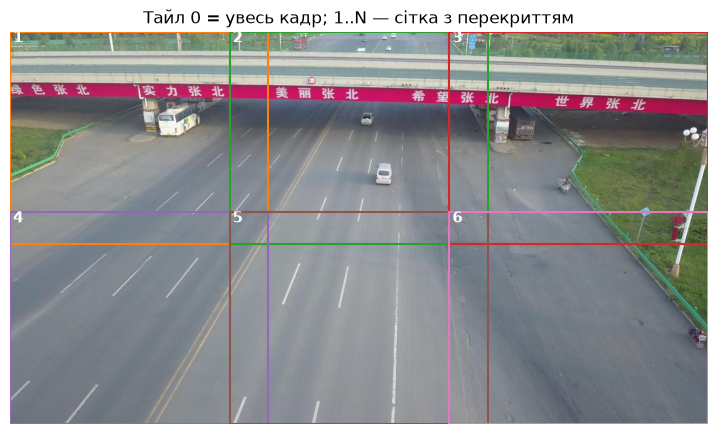

In [5]:
tiles = A.make_tiles(kf, TILE_GRID, TILE_OVERLAP)
tpf = tiles.groupby("kf_id").size().max()
w_med = int(kf["width"].median())
tile_w = int((tiles[tiles.tile_idx > 0].x1 - tiles[tiles.tile_idx > 0].x0).median()) if TILE_GRID else w_med
print(f"Тайлів: {len(tiles)} ({tpf} на кадр)")
print(f"Ширина кадру ~{w_med}px -> 224: стиснення x{w_med / 224:.1f};  тайл ~{tile_w}px -> 224: x{tile_w / 224:.1f}")
A.show_tiles(kf.iloc[len(kf) // 2], tiles, "Тайл 0 = увесь кадр; 1..N — сітка з перекриттям")

## 2. Ground truth

**VisDrone:** розмітка — bbox + категорія на кожному кадрі. Кадр вважаємо релевантним запиту `truck`,
якщо на ньому є вантажівка з короткою стороною ≥ `MIN_PX` і без сильної оклюзії.
Сусідні релевантні кадри одного кліпу зливаються в **подію** — одну ціль, яку оператор має побачити хоча б раз.

**Власне відео:** файли в `artifacts/aerial_video/`, GT — `gt/own_queries.csv` — по рядку на кожен інтервал, де ціль видно
(шаблон: `gt/own_queries_template.csv`).

`prevalence` — частка кадрів з ціллю. На архіві, де ціль у 1 % кадрів, випадкове ранжування дає P@10 ≈ 0.01:
порівнюйте метрики з цим числом, а не з нулем.

In [6]:
if DATASET == "visdrone":
    gt = A.load_visdrone_gt(kf, sources, min_px=MIN_PX)
else:
    gt = A.load_csv_gt(kf, OWN_GT_CSV)
gt = {q: g for q, g in gt.items() if g["events"]}
assert gt, "Немає жодного запиту з подіями — перевірте GT"
display(A.gt_summary(gt, len(kf)))

,query,text,relevant_frames,events,prevalence
1,bus,a bus,653,34,0.213
4,bicycle,a person riding a bicycle,1129,65,0.368
0,truck,a truck,1385,58,0.451
3,tricycle,a three-wheeled cargo tricycle,1528,60,0.497
5,motorcycle,a motorcycle,1798,75,0.585
2,van,a van,1831,74,0.596
6,person,people walking,2296,85,0.747
7,car,a car,2658,72,0.865


## 3. Моделі та індексація

Усі три моделі завантажуються через OpenCLIP, тому інтерфейс однаковий.
Кадр подається **letterbox** (`resize_mode="longest"`), а не center-crop: інакше з кадру 16:9 зникає 44 % ширини.

> **Про чесність порівняння.** SigLIP 2 B/**16** на 224 px має 196 патчів, а B/**32** — 49:
> SigLIP 2 бачить дрібніші деталі й рахує ~4× більше. Це практичне порівняння «що взяти з полиці»,
> а не порівняння методів навчання за рівних умов.

In [7]:
# Прогрес-бар на кожну модель. Ембеддинги пишуться в outputs/demo2/emb/ частинами:
# перервали — наступний запуск продовжить з місця зупинки; нічого не змінили — візьме готові з кешу.
encoders, embs, indices = {}, {}, {}
rows = []
for name in MODELS:
    t0 = time.time()
    enc = A.Encoder(name, SIZE, models_dir=MODELS_DIR, device=DEVICE, random_weights=SMOKE)
    t_load = time.time() - t0
    E = A.embed_tiles(enc, kf, tiles, CACHE_DIR / "emb", batch_size=BATCH)
    encoders[name], embs[name], indices[name] = enc, E, A.build_flat_index(E)
    rows.append(dict(model=name, arch=enc.arch, params_M=enc.n_params / 1e6, dim=enc.dim, vectors=len(E),
                     input=str(enc.input_size), device=enc.device, img_per_s=enc.img_per_s, load_s=t_load,
                     cached=enc.cached))
pd.DataFrame(rows)

siglip2-base:   0%|          | 0/21504 [00:00<?, ?тайл/s]

remoteclip-base:   0%|          | 0/21504 [00:00<?, ?тайл/s]

skyclip-base:   0%|          | 0/21504 [00:00<?, ?тайл/s]

,model,arch,params_M,dim,vectors,input,device,img_per_s,load_s,cached
0,siglip2,ViT-B-16-SigLIP2,375.188,768,21504,"(224, 224)",cuda,53.843,46.407,False
1,remoteclip,ViT-B-32,151.277,512,21504,"(224, 224)",cuda,91.731,2.268,False
2,skyclip,ViT-B-32,151.277,512,21504,"(224, 224)",cuda,75.338,3.958,False


In [8]:
# Швидкість пошуку: повний перебір по всіх тайлах — FAISS проти «голого» numpy.
# Усі три способи рахують те саме: cos = E @ q (вектори нормовані), потім топ-K.
name0 = MODELS[0]
q = encoders[name0].text_query("a truck")
K, REPS = 50, 50

def bench(fn, reps=REPS):
    fn()                                   # прогрів: кеші, потоки BLAS / OpenMP
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps * 1e3

def topk_sort(E, Q):                       # повне сортування всіх N оцінок: O(N log N)
    S = Q @ E.T
    return np.argsort(-S, axis=1)[:, :K]

def topk_partition(E, Q):                  # частковий відбір топу: O(N), сортуємо лише K
    S = Q @ E.T
    top = np.argpartition(-S, K, axis=1)[:, :K]
    order = np.argsort(-np.take_along_axis(S, top, 1), axis=1)
    return np.take_along_axis(top, order, 1)

def topk_faiss(index, Q):
    return index.search(np.ascontiguousarray(Q, dtype="float32"), K)[1]

def compare(E, index, label):
    rng = np.random.default_rng(0)
    batch = E[rng.choice(len(E), 64)]      # 64 запити пакетом (вектори з архіву — для таймінгу байдуже які)
    rows = []
    for qname, Q in [("1 запит", q[None]), ("64 запити", batch)]:
        for method, fn in [("numpy argsort", lambda: topk_sort(E, Q)),
                           ("numpy argpartition", lambda: topk_partition(E, Q)),
                           ("FAISS IndexFlatIP", lambda: topk_faiss(index, Q))]:
            rows.append(dict(vectors=f"{len(E):,} ({label})", queries=qname, method=method,
                             ms_per_query=bench(fn) / len(Q)))
    # той самий топ: порівнюємо оцінки (порядок рівних оцінок у різних методів може відрізнятись)
    S = q @ E.T
    same = np.allclose(np.sort(S[topk_partition(E, q[None])[0]]), np.sort(S[topk_faiss(index, q[None])[0]]), atol=1e-5)
    return rows, same

E0 = np.ascontiguousarray(embs[name0], dtype="float32")
rows, same = compare(E0, indices[name0], "наш архів")

# Як це масштабується: випадкові нормовані вектори тієї ж розмірності (швидкість від вмісту не залежить)
N_BIG = 20_000 if SMOKE else 200_000       # ≈ 0.6 ГБ для dim=768; зменшіть, якщо бракує пам'яті
E_big = np.random.default_rng(1).standard_normal((N_BIG, E0.shape[1]), dtype=np.float32)
E_big /= np.linalg.norm(E_big, axis=1, keepdims=True)
rows_big, same_big = compare(E_big, A.build_flat_index(E_big), "синтетика")
del E_big

T = pd.DataFrame(rows + rows_big)
print(f"Топ-{K} однаковий у numpy і FAISS: {same and same_big}")
T.pivot_table(index=["vectors", "queries"], columns="method", values="ms_per_query", sort=False).round(3)

Топ-50 однаковий у numpy і FAISS: True


method                         numpy argsort  numpy argpartition  \
vectors             queries                                        
21,504 (наш архів)  1 запит            9.023               6.631   
                    64 запити          3.435               1.916   
200,000 (синтетика) 1 запит           71.929              46.596   
                    64 запити          7.139               2.702   

method                         FAISS IndexFlatIP  
vectors             queries                       
21,504 (наш архів)  1 запит               14.276  
                    64 запити              5.185  
200,000 (синтетика) 1 запит              120.493  
                    64 запити             22.423

**Що видно з таблиці.** Точний перебір (`IndexFlatIP`) — це та сама операція, що й `E @ q` у numpy: множення матриці
на вектор через BLAS і відбір топу. Тому на точному пошуку FAISS не виграє, а на одиночному запиті часто програє
через накладні витрати на потоки OpenMP. Вирішує не бібліотека, а алгоритм:
- `argpartition` замість повного `argsort` — відбір топу за O(N) замість O(N log N);
- **пакет запитів** — множення матриці на матрицю завантажує процесор краще, ніж окремі `E @ q`.

FAISS потрібен, коли точний перебір уже не вміщається в бюджет: **наближені індекси** (IVF, HNSW — мільйони векторів
за мілісекунди ціною частини recall), **PQ-стиснення** (розділ 8), GPU, додавання й видалення за id, збереження індексу на диск.
На нашому архіві з кількох тисяч векторів numpy цілком досить.

> Таймінги чесні лише на вільній машині: поки в іншому процесі рахуються ембеддинги, FAISS із 16 потоками OpenMP
> гальмує в десятки разів сильніше за numpy — перевірено на собі.

## 4. Пошук

`ask("...")` показує топ кадрів для кожної моделі. Жовта рамка — тайл, який дав максимальний cos.
Для запитів із GT зелений заголовок (✓) — кадр з ціллю, червоний (✗) — без.

Запити для показу на занятті: позитивні описи з ракурсом. Негації, рахунок і «ліворуч від»
лишаємо для батареї відмов (Демо 1).

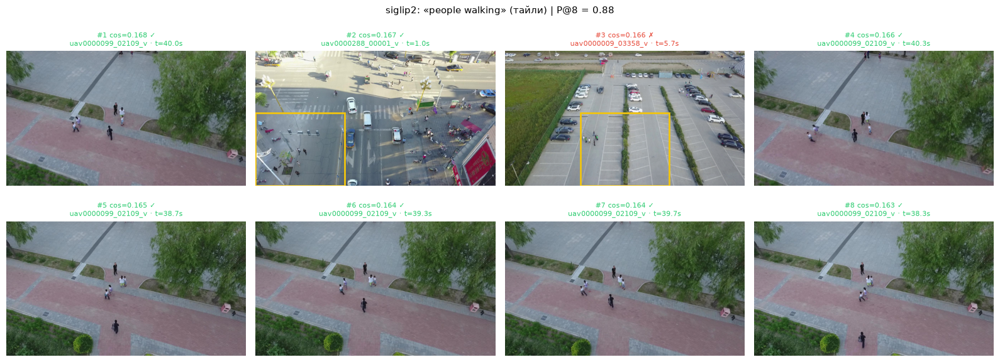

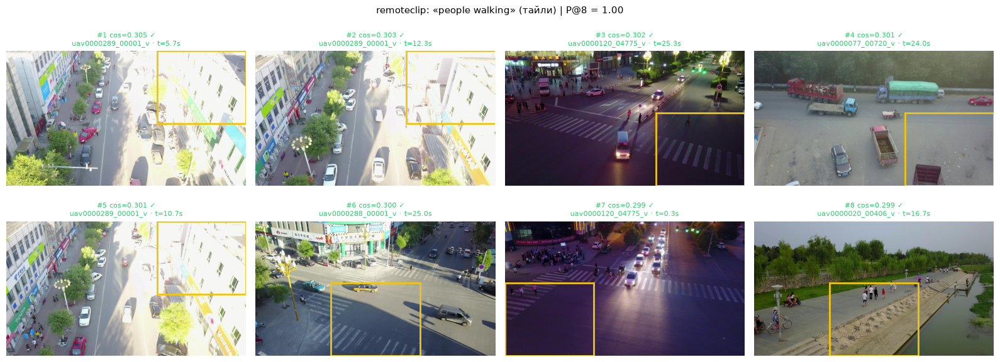

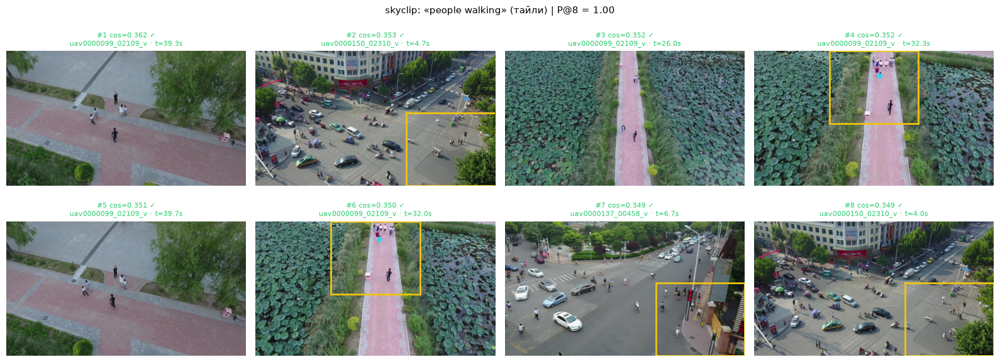

In [9]:
def ask(text, k=8, use_tiles=True, templates=A.AERIAL_TEMPLATES, models=None, gt_query=None):
    rel = gt[gt_query]["relevant"] if gt_query else None
    for name in models or MODELS:
        qv = encoders[name].text_query(text, templates)
        res = A.search(indices[name], qv, tiles, kf, k=k, use_tiles=use_tiles)
        hit = f" | P@{k} = {np.mean([r in rel for r in res.kf_id]):.2f}" if rel is not None else ""
        A.show_results(res, f"{name}: «{text}» {'(тайли)' if use_tiles else '(увесь кадр)'}{hit}",
                       relevant=rel, ncols=4)

demo_q = max(gt, key=lambda q: len(gt[q]["events"]))
ask(gt[demo_q]["text"], gt_query=demo_q)

In [10]:
# Інтерактивна панель (потрібен ipywidgets). Без нього просто викликайте ask("...").
# Вибір запиту з GT підставляє його текст і вмикає позначки ✓/✗ та P@k; змінили текст — позначки зникають.
A.search_box(
    lambda text, aerial, **kw: ask(text, templates=A.AERIAL_TEMPLATES if aerial else A.PLAIN_TEMPLATES, **kw),
    models=MODELS,
    gt_texts={q: g["text"] for q, g in gt.items()},
)

## 5. Кількісне порівняння

Для кожної моделі прогоняємо всі запити з GT у чотирьох конфігураціях:
промпт **plain** (`"a truck"`) або **aerial** (ансамбль із 6 формулювань), вхід **кадр** або **тайли**.

- **EventR@50** — частка подій, які потрапили в перші 50 кадрів видачі (те, що реально побачить оператор).
- **P@10** — скільки сміття на першому екрані.
- **AP** — середня точність по всьому ранжуванню.

In [11]:
CONFIGS = [("plain", A.PLAIN_TEMPLATES), ("aerial", A.AERIAL_TEMPLATES)]
qvecs = {(m, mode, q): encoders[m].text_query(gt[q]["text"], tpls)
         for m in MODELS for mode, tpls in CONFIGS for q in gt}

recs = []
for m in MODELS:
    for mode, _ in CONFIGS:
        for q in gt:
            ts = A.all_tile_scores(indices[m], qvecs[(m, mode, q)])
            for use_tiles in ([False, True] if TILE_GRID else [False]):
                fs = A.frame_scores(ts, tiles, len(kf), use_tiles=use_tiles)
                recs.append(dict(model=m, prompt=mode, input="tiles" if use_tiles else "frame", query=q,
                                 **A.rank_metrics(fs, gt[q])))
R = pd.DataFrame(recs)
summary = (R.groupby(["model", "prompt", "input"])[["EventR@10", "EventR@50", "P@10", "AP"]]
             .mean().sort_values("EventR@50", ascending=False))
summary

EventR@10  EventR@50   P@10     AP
model      prompt input                                    
skyclip    aerial tiles      0.061      0.187  0.938  0.709
siglip2    plain  tiles      0.062      0.180  0.875  0.763
           aerial tiles      0.059      0.176  0.863  0.723
skyclip    plain  tiles      0.059      0.171  0.925  0.709
remoteclip aerial tiles      0.059      0.165  0.588  0.601
           plain  tiles      0.065      0.163  0.650  0.600
siglip2    plain  frame      0.053      0.144  0.800  0.694
           aerial frame      0.048      0.115  0.775  0.670
skyclip    plain  frame      0.027      0.111  0.713  0.651
           aerial frame      0.030      0.101  0.713  0.641
remoteclip aerial frame      0.041      0.090  0.537  0.575
           plain  frame      0.024      0.059  0.475  0.533

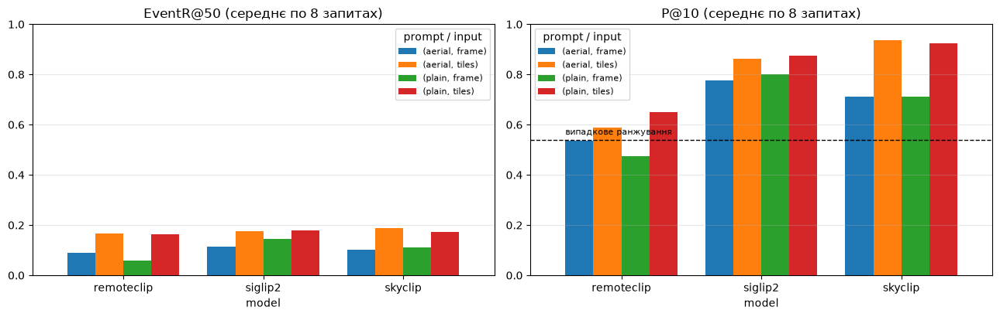

In [12]:
# Випадкове ранжування: очікувана P@k = prevalence запиту
base_p10 = np.mean([len(v["relevant"]) / len(kf) for v in gt.values()])
A.plot_metrics(R, ["EventR@50", "P@10"], baselines={"P@10": base_p10})

In [13]:
# По запитах: де модель провалюється (найкраща конфігурація для кожної моделі)
best_cfg = summary.reset_index().groupby("model").first()[["prompt", "input"]]
print("Найкраща конфігурація:\n", best_cfg, "\n")
sel = R.merge(best_cfg.reset_index(), on=["model", "prompt", "input"])
per_q = sel.pivot(index="query", columns="model", values="EventR@50")
per_q["prevalence"] = R.groupby("query")["prevalence"].first()
per_q.sort_values("prevalence")

Найкраща конфігурація:
             prompt  input
model                    
remoteclip  aerial  tiles
siglip2      plain  tiles
skyclip     aerial  tiles 



model,remoteclip,siglip2,skyclip,prevalence
query,,,,
bus,0.176,0.294,0.294,0.213
bicycle,0.154,0.169,0.169,0.368
truck,0.155,0.172,0.103,0.451
tricycle,0.217,0.167,0.267,0.497
motorcycle,0.107,0.173,0.173,0.585
van,0.176,0.189,0.203,0.596
person,0.129,0.082,0.094,0.747
car,0.208,0.194,0.194,0.865


## 6. Пороги: розподіли сирого cos

Слайд 47: пороги ставимо за виміряними розподілами, окремо для кожної моделі й запиту.
Шкали в моделей **різні** (у SigLIP 2 косинуси помітно нижчі, ніж у CLIP-подібних) — тому поріг однієї моделі
не переноситься на іншу. Нижче для кожної моделі: поріг, що зберігає 90 % кадрів з ціллю, і скільки
порожніх кадрів при цьому піде оператору.

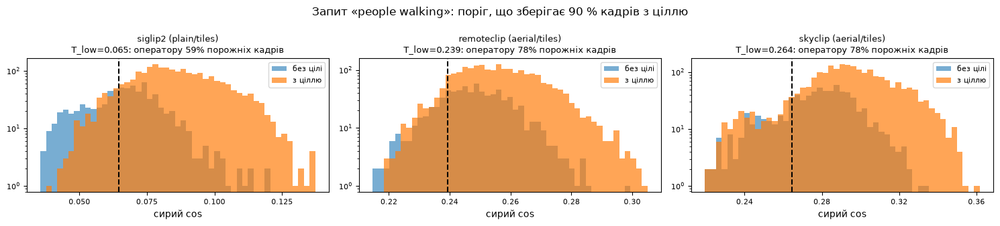

In [14]:
q = demo_q
rel_mask = np.zeros(len(kf), bool); rel_mask[list(gt[q]["relevant"])] = True
panels = []
for m in MODELS:
    mode, inp = best_cfg.loc[m, "prompt"], best_cfg.loc[m, "input"]
    fs = A.frame_scores(A.all_tile_scores(indices[m], qvecs[(m, mode, q)]), tiles, len(kf), use_tiles=(inp == "tiles"))
    t_low = np.quantile(fs[rel_mask], 0.10)       # поріг, що зберігає 90 % кадрів з ціллю
    load = (fs[~rel_mask] >= t_low).mean()          # частка порожніх кадрів, які пройдуть поріг
    panels.append(dict(title=f"{m} ({mode}/{inp})", scores=fs, t_low=t_low, load=load))
A.plot_thresholds(panels, rel_mask, f"Запит «{gt[q]['text']}»: поріг, що зберігає 90 % кадрів з ціллю")

## 7. Пошук «за зразком»: кадр → кадри

Оператор знайшов одну ціль і хоче решту схожих. Беремо найкращий тайл першої видачі як запит-зображення.

Зразок вирізано з того самого архіву, тож сам кадр і сусідні кадри тієї ж події знайдуться тривіально — це не пошук,
а впізнавання себе. Тому виключаємо з видачі й з GT усю подію зразка та кадри того самого кліпу в межах `EXCLUDE_S` секунд.
Для свого фото (не з архіву) виключати нічого.

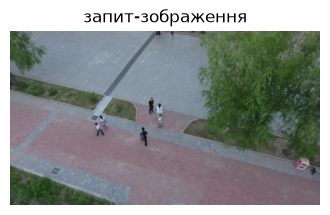

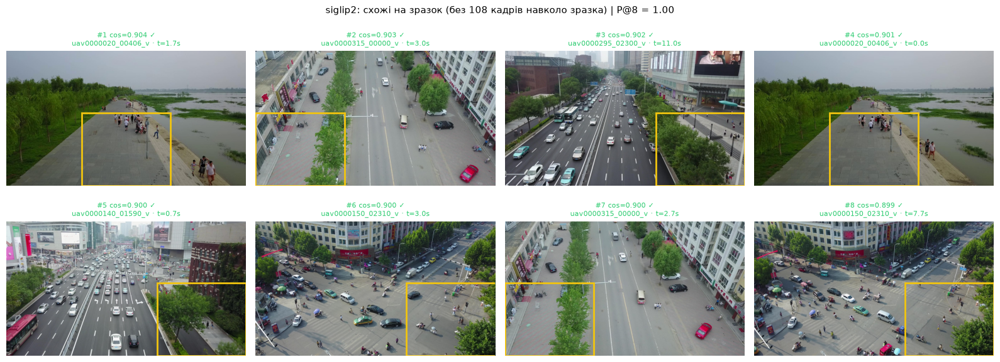

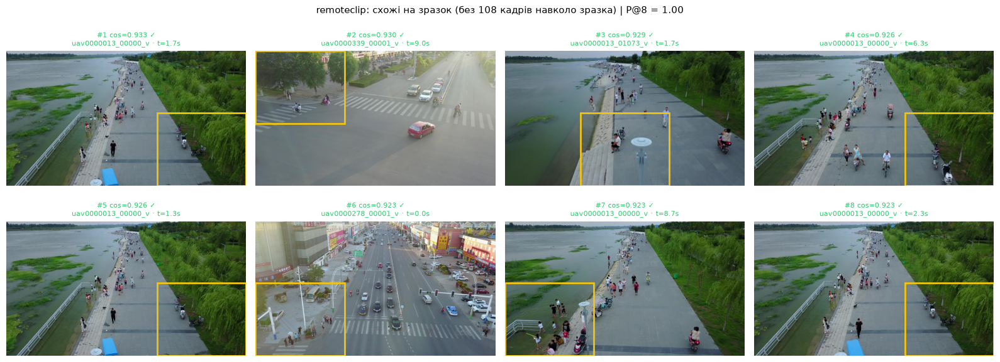

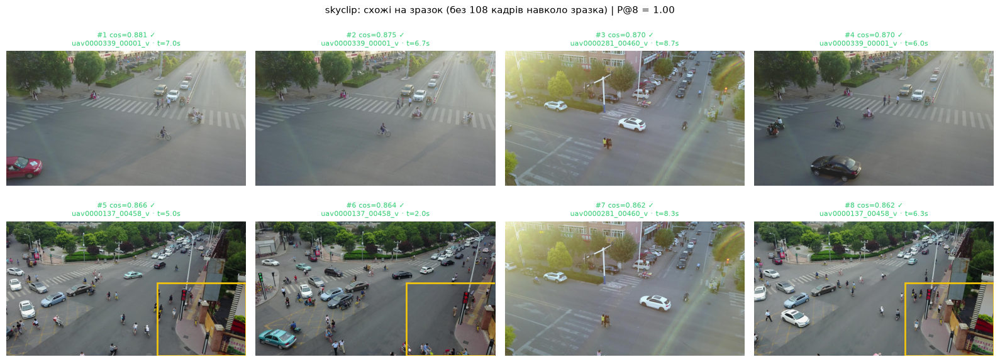

In [15]:
EXCLUDE_S = 5.0

def near_frames(kf_id, gt_query=None):
    """Кадр-зразок, сусіди з того ж кліпу в межах ±EXCLUDE_S і вся його GT-подія — їх знайти тривіально."""
    r = kf.set_index("kf_id").loc[kf_id]
    near = kf[(kf.source_id == r.source_id) & ((kf.t_sec - r.t_sec).abs() <= EXCLUDE_S)]
    excl = set(near.kf_id.astype(int)) | {int(kf_id)}
    for ev in (gt[gt_query]["events"] if gt_query else []):
        if kf_id in ev:
            excl |= set(ev)
    return excl

def ask_image(crop, models=None, k=8, use_tiles=True, src_kf=None, gt_query=None):
    excl = near_frames(src_kf, gt_query) if src_kf is not None else set()
    rel = gt[gt_query]["relevant"] - excl if gt_query else None
    for name in models or MODELS:
        res = A.search(indices[name], encoders[name].image_query(crop), tiles, kf, k=k, use_tiles=use_tiles, exclude=excl)
        hit = f" | P@{k} = {np.mean([r in rel for r in res.kf_id]):.2f}" if rel is not None else ""
        note = f" (без {len(excl)} кадрів навколо зразка)" if excl else ""
        A.show_results(res, f"{name}: схожі на зразок{note}{hit}", relevant=rel)

m = MODELS[0]
r0 = A.search(indices[m], qvecs[(m, "aerial", demo_q)], tiles, kf, k=1).iloc[0]
crop = Image.open(r0.path).crop((r0.x0, r0.y0, r0.x1, r0.y1))
A.show_image(crop, "запит-зображення")
ask_image(crop, src_kf=int(r0.kf_id), gt_query=demo_q)

### Інтерактивно: своє зображення і свій регіон

Оберіть кадр з архіву повзунком або завантажте своє фото кнопкою **«Обрати фото»** (JPG / PNG),
протягніть мишею рамку навколо цілі й натисніть **«Шукати схожі»**. Регіон також можна підправити слайдерами `x` / `y`.
Миша працює з пакетом `ipyevents`; без нього лишаються слайдери.

Що спробувати: виділити одну машину проти цілого перехрестя; той самий об'єкт з різних кадрів;
фото з інтернету чи зі свого дрона — наскільки доменний розрив б'є по кожній моделі.

In [16]:
# Стартує з кадру й регіону, знайдених вище. Без ipywidgets просто викликайте ask_image(crop).
img_panel = A.image_search_panel(
    ask_image, kf, models=MODELS,
    gt_texts={q: g["text"] for q, g in gt.items()},
    start_kf=int(r0.kf_id), start_box=(int(r0.x0), int(r0.y0), int(r0.x1), int(r0.y1)),
)

## 8. Вузький канал: PQ-коди замість векторів (кейс 1)

На борту лишається лише PQ-код вектора: `M × nbits / 8` байт (64 Б при `M=64, nbits=8`).
Скільки пошуку втрачаємо і скільки повертає дозапит повних векторів для топу видачі?

> У реальній системі кодова книга вчиться на землі на великому архіві й завантажується на борт до вильоту.
> Тут вчимо її на **всіх тайлах** архіву, навіть якщо ранжуємо лише цілі кадри. FAISS радить ≥ 39 векторів на центроїд
> (≈ 10 тис. для 8 біт); на VisDrone val + test-dev їх менше, тож `build_pq` попередить: кодова книга грубша,
> ніж була б у бою, і втрати PQ тут — оцінка зверху. Фактичний розмір коду друкується нижче.

In [17]:
m = summary.reset_index().iloc[0]["model"]          # найкраща модель за EventR@50
mode, inp = best_cfg.loc[m, "prompt"], best_cfg.loc[m, "input"]
use_t = inp == "tiles"
# PQ будуємо по тих самих векторах, що йдуть у ранжування: тайли або лише цілі кадри (тайл 0)
rows_sel = np.arange(len(tiles)) if use_t else np.flatnonzero(tiles["tile_idx"].to_numpy() == 0)
E_sel = embs[m][rows_sel]
pq, info = A.build_pq(E_sel, M=64, nbits=8, train=embs[m])   # кодова книга — на всіх тайлах
print(m, f"({mode}/{inp})", info)

def to_full(s_sel):
    s = np.full(len(tiles), -np.inf, dtype=np.float32)
    s[rows_sel] = s_sel
    return s

rerank_n = 100 * (tpf if use_t else 1)     # ~топ-100 кадрів
recs = []
for q in gt:
    qv = qvecs[(m, mode, q)]
    variants = {
        "Flat (повні вектори)": A.all_tile_scores(indices[m], qv),
        f"PQ {info['code_bytes']:.0f} Б": to_full(A.pq_tile_scores(pq, qv)),
        "PQ + дозапит топ-100": to_full(A.pq_tile_scores(pq, qv, E_sel, rerank_top=rerank_n)),
    }
    for vname, ts in variants.items():
        fs = A.frame_scores(ts, tiles, len(kf), use_tiles=use_t)
        recs.append(dict(variant=vname, query=q, **A.rank_metrics(fs, gt[q])))
P = pd.DataFrame(recs).groupby("variant", sort=False)[["EventR@50", "P@10", "AP"]].mean()
P

skyclip (aerial/tiles) {'M': 64, 'nbits': 8, 'code_bytes': 64.0, 'fp16_bytes': 1024, 'n_train': 21504}


,EventR@50,P@10,AP
variant,,,
Flat (повні вектори),0.187,0.938,0.709
PQ 64 Б,0.201,0.900,0.679
PQ + дозапит топ-100,0.190,0.938,0.688


In [18]:
meta_b = 16
msg = info["code_bytes"] + meta_b
fp16 = info["fp16_bytes"] + meta_b
rows = []
for kbps in [1.5, 3.0, 6.0]:
    Bps = kbps * 1000 / 8
    rows.append({"канал, кбіт/с": kbps, "PQ-повідомлень/с": Bps / msg, "FP16-векторів/с": Bps / fp16})
print(f"Повідомлення: PQ {msg:.0f} Б (код {info['code_bytes']:.0f} + метадані {meta_b}) vs FP16 {fp16:.0f} Б")
pd.DataFrame(rows)

Повідомлення: PQ 80 Б (код 64 + метадані 16) vs FP16 1040 Б


,"канал, кбіт/с",PQ-повідомлень/с,FP16-векторів/с
0,1.5,2.344,0.180
1,3.0,4.688,0.361
2,6.0,9.375,0.721


## Що сказати на занятті

1. **Пошук працює і без розмітки:** текстовий запит звужує архів до кількох десятків кадрів. Але дивіться на EventR@50
   поряд із `prevalence`, а не на «красиві» картинки першої видачі.
2. **Домен важить, але не автоматично перемагає:** доменні ваги (RemoteCLIP / SkyCLIP) навчені переважно на надирі з
   великої висоти; на косому ракурсі низьких дронів перевага не гарантована. Міряйте на своїх кадрах.
3. **Пікселі важать більше за модель:** перехід «кадр → тайли» часто дає більший приріст, ніж заміна моделі (слайд 23).
4. **Промпт із ракурсом — безкоштовний приріст** (або ні — це теж треба виміряти).
5. **Пороги — по сирому cos, окремо для моделі й запиту.** Шкали моделей несумісні.
6. **PQ + дозапит топу** повертає більшу частину якості при десятках байт на кадр (див. `info['code_bytes']`) — це і є кейс 1.

**Завдання для студентів:** додати 3 власні запити до GT; порівняти `SIZE="large"`; поставити `TILE_GRID=(3, 4)`
і порахувати, скільки пікселів займає ціль після ресайзу тайла; повторити розділ 8 з `M=32`.